In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

In [3]:
sys = Moire(theta_deg=1.5, psi_deg=26.0, V=8, n_shells=10)

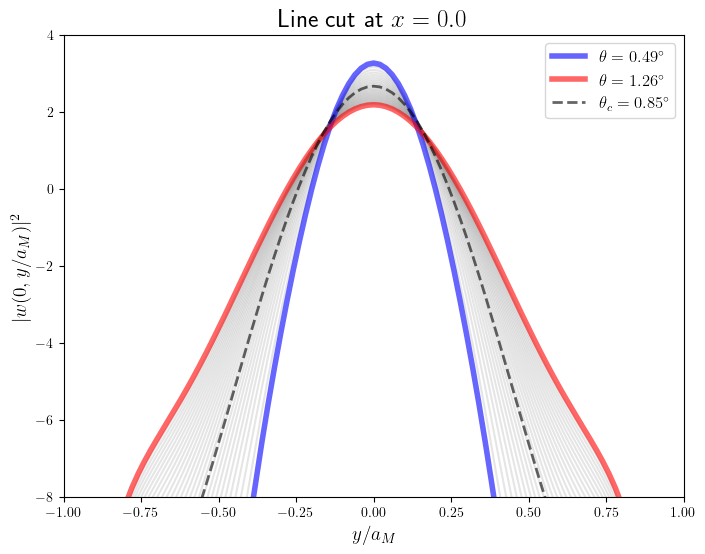

In [4]:
scale = 2.0
Nx = 201
Ny = 201
theta_list = [0.5, 0.7, 1.0, 1.2]
thetasquare = np.linspace(0.03, .2, 30)#[0.05, 0.09, 0.15]#np.linspace(0.01, 0.2, 4)

plt.figure(figsize=(8, 6))

for th in thetasquare:
    sys.theta_deg = np.sqrt(th * sys.V)
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [X.min(), X.max(), Y.min(), Y.max()]
    k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

    wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
    density = np.abs(wannier) ** 2
    # fun = lambda x, y: 1
    # print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", sys.theta_deg)

    ix0 = np.argmin(np.abs(x))        # column closest to x = 0
    density_cut = density[:, ix0]     # varies along y

    if th == thetasquare[0]:
        plt.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="blue", alpha=0.6, zorder=10, linewidth=4, label=f"$\\theta = {sys.theta_deg:.2f}^\\circ$")
    elif th == thetasquare[-1]:
        plt.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="red", alpha=0.6, zorder=10, linewidth=4, label=f"$\\theta = {sys.theta_deg:.2f}^\\circ$")
    else:
        plt.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="gray", alpha=0.2)

theta_c = np.sqrt(0.09 * sys.V)
sys.theta_deg = theta_c
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [X.min(), X.max(), Y.min(), Y.max()]
k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
density = np.abs(wannier) ** 2
# fun = lambda x, y: 1
# print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", sys.theta_deg)

ix0 = np.argmin(np.abs(x))        # column closest to x = 0
density_cut = density[:, ix0]     # varies along y
plt.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="k", alpha=0.6, zorder=10, linewidth=2, linestyle="--", label=f"$\\theta_c = {theta_c:.2f}^\\circ$")

plt.xlabel(r'$y / a_M$', fontsize=14)
plt.ylabel(r'$|w(0, y/a_M)|^2$', fontsize=14)
plt.title(f'Line cut at $x = {x[ix0]:.1f}$', fontsize=18)
plt.xlim([-1, 1])
plt.ylim([-8, 4])
plt.legend(fontsize=12)
#plt.tight_layout()
plt.show()

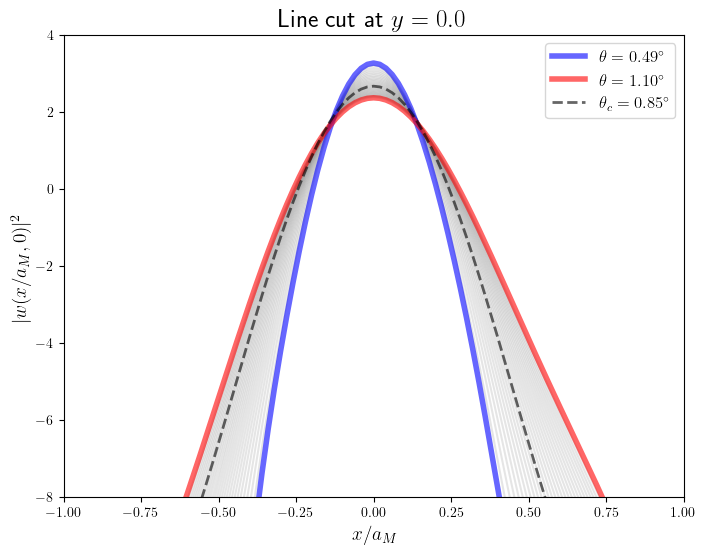

In [5]:
scale = 2.0
Nx = 201
Ny = 201
theta_list = [0.5, 0.7, 1.0, 1.2]
thetasquare = np.linspace(0.03, .15, 30)#[0.05, 0.09, 0.15]#np.linspace(0.01, 0.2, 4)

plt.figure(figsize=(8, 6))

for th in thetasquare:
    sys.theta_deg = np.sqrt(th * sys.V)
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [X.min(), X.max(), Y.min(), Y.max()]
    k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

    wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
    density = np.abs(wannier) ** 2
    # fun = lambda x, y: 1
    # print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", sys.theta_deg)

    iy0 = np.argmin(np.abs(y))        # column closest to y = 0
    density_cut = density[iy0, :]     # varies along y

    if th == thetasquare[0]:
        plt.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="blue", alpha=0.6, zorder=10, linewidth=4, label=f"$\\theta = {sys.theta_deg:.2f}^\\circ$")
    elif th == thetasquare[-1]:
        plt.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="red", alpha=0.6, zorder=10, linewidth=4, label=f"$\\theta = {sys.theta_deg:.2f}^\\circ$")
    else:
        plt.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="gray", alpha=0.2)

theta_c = np.sqrt(0.09 * sys.V)
sys.theta_deg = theta_c
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [X.min(), X.max(), Y.min(), Y.max()]
k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
density = np.abs(wannier) ** 2
# fun = lambda x, y: 1
# print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", sys.theta_deg)

iy0 = np.argmin(np.abs(y))        # column closest to y = 0
density_cut = density[:, iy0]     # varies along y
plt.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="k", alpha=0.6, zorder=10, linewidth=2, linestyle="--", label=f"$\\theta_c = {theta_c:.2f}^\\circ$")

plt.xlabel(r'$x / a_M$', fontsize=14)
plt.ylabel(r'$|w(x / a_M, 0)|^2$', fontsize=14)
plt.title(f'Line cut at $y = {y[iy0]:.1f}$', fontsize=18)
plt.xlim([-1, 1])
plt.ylim([-8, 4])
plt.legend(fontsize=12)
#plt.tight_layout()
plt.show()

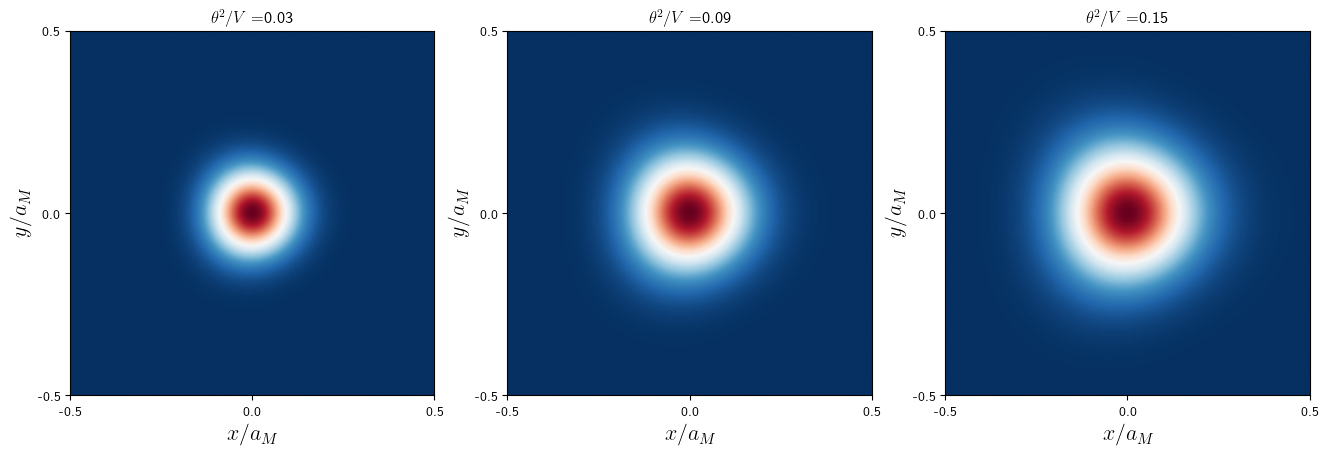

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
scale = .5

theta_list = [thetasquare[0], 0.09, thetasquare[-1]]

for th, ax in zip(theta_list, axes):
    sys.theta_deg = np.sqrt(th * sys.V)
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [X.min(), X.max(), Y.min(), Y.max()]

    im = sys.plot_wannier_function(ax, X, Y, k_points)
    #sys.plot_triangular_lattice(ax, extent)
    ax.set_title(r"$\theta^2/V = $"+f"{th:.2f}")
    
    aM_i = sys.aM
    ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax.set_xlabel(r'$x/a_M$', fontsize=16)
    ax.set_ylabel(r'$y/a_M$', fontsize=16)

Text(0, 0.5, '$y/a_M$')

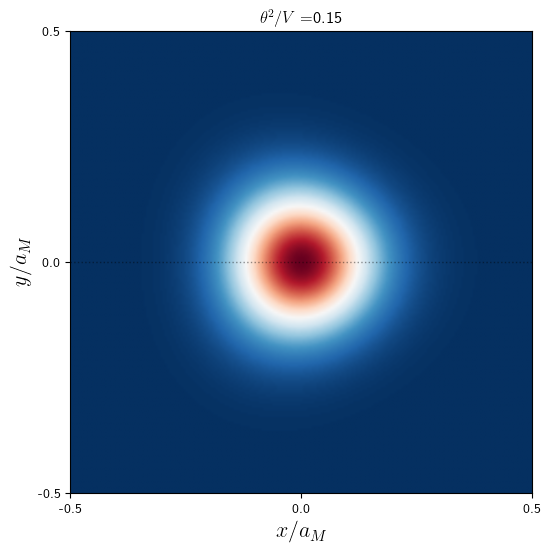

In [15]:
fig, ax = plt.subplots(figsize=(16, 6))
scale = .5


sys.theta_deg = np.sqrt(0.09 * sys.V)
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [X.min(), X.max(), Y.min(), Y.max()]

iy0 = np.argmin(np.abs(y))        # column closest to y = 0

im = sys.plot_wannier_function(ax, X, Y, k_points)
#sys.plot_triangular_lattice(ax, extent)
ax.axhline(y[iy0], color="black", ls=":", lw=1, alpha=0.4)   # line at y ≈ 0
ax.set_title(r"$\theta^2/V = $"+f"{th:.2f}")
aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)

Text(0, 0.5, '$y/a_M$')

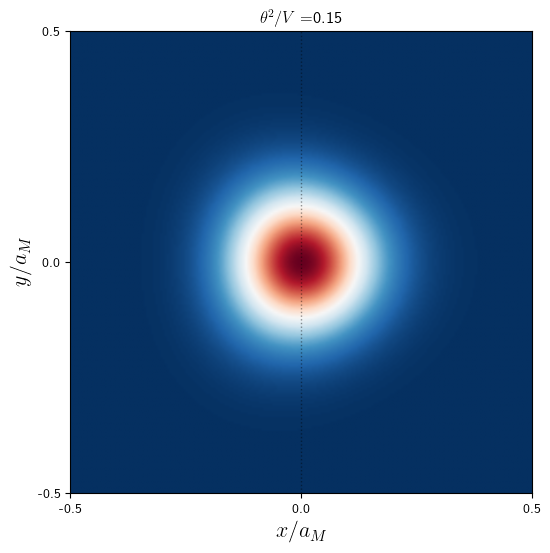

In [16]:
fig, ax = plt.subplots(figsize=(16, 6))
scale = .5


sys.theta_deg = np.sqrt(0.09 * sys.V)
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [X.min(), X.max(), Y.min(), Y.max()]

ix0 = np.argmin(np.abs(x))        # column closest to x = 0

im = sys.plot_wannier_function(ax, X, Y, k_points)
#sys.plot_triangular_lattice(ax, extent)
ax.axvline(x[ix0], color="black", ls=":", lw=1, alpha=0.4)   # line at x ≈ 0
ax.set_title(r"$\theta^2/V = $"+f"{th:.2f}")
aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)